# RBM input validation and Baseline Apriori (FP-Growth) model

In [1]:
import os
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import fpgrowth, association_rules

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8')
sns.set_palette("husl")
%matplotlib inline

In [2]:
VOCAB_SIZE = 1001
RARE_IDX = 0
K_VALUES = [1, 3, 5, 9]
MIN_SUPPORT = 0.001
MIN_CONFIDENCE = 0.5
EXPLODE_THRESHOLD = 1e3
VANISH_THRESHOLD = 1e-6
DEAD_FEATURE_STD = 1e-8
DEAD_FEATURE_WARN = 0.10

PROC_DIR = '../data/processed'
DENSE_PATH = f'{PROC_DIR}/X_rbm_dense.npy'
VIS_DIR = '../data/visualizations'
PRED_DIR = '../data/predictions'
REPORT_DIR = '../data/reports'

for d in [VIS_DIR, PRED_DIR, REPORT_DIR]:
    os.makedirs(d, exist_ok=True)

In [3]:
X_padded = np.load(f'{PROC_DIR}/X_padded.npy')
Y = np.load(f'{PROC_DIR}/y_target.npy')

assert X_padded.ndim == 3 and X_padded.shape[2] == VOCAB_SIZE
assert Y.ndim == 2 and Y.shape == (X_padded.shape[0], VOCAB_SIZE)

print(f"X_padded shape: {X_padded.shape}")
print(f"Y shape: {Y.shape}")
print(f"Users: {X_padded.shape[0]}, sequence length: {X_padded.shape[1]}, vocab: {X_padded.shape[2]}")

X_padded shape: (14074, 10, 1001)
Y shape: (14074, 1001)
Users: 14074, sequence length: 10, vocab: 1001


In [4]:
def check_array(X, name, binary=False):
    report = {'name': name, 'shape': list(X.shape), 'dtype': str(X.dtype)}
    report['nan_count'] = int(np.isnan(X).sum())
    report['inf_count'] = int(np.isinf(X).sum())
    failures, warns = [], []
    if report['nan_count'] > 0:
        failures.append('NaN values present')
    if report['inf_count'] > 0:
        failures.append('Inf values present')
    finite = X[np.isfinite(X)]
    if finite.size == 0:
        failures.append('no finite values')
        report.update({'failures': failures, 'warnings': warns, 'status': 'FAIL'})
        return report
    abs_vals = np.abs(finite)
    report['min'] = float(finite.min())
    report['max'] = float(finite.max())
    report['mean'] = float(finite.mean())
    report['std'] = float(finite.std())
    report['max_abs'] = float(abs_vals.max())
    report['vanishing_ratio'] = float(np.mean(abs_vals < VANISH_THRESHOLD))
    report['exploding_ratio'] = float(np.mean(abs_vals > EXPLODE_THRESHOLD))
    flat = X.reshape(-1, X.shape[-1])
    feature_std = flat.std(axis=0)
    report['dead_feature_ratio'] = float(np.mean(feature_std < DEAD_FEATURE_STD))
    report['all_zero_rows_ratio'] = float(np.mean(~flat.any(axis=1)))
    if report['exploding_ratio'] > 0:
        failures.append(f"exploding values: |x| > {EXPLODE_THRESHOLD:g} in {report['exploding_ratio']:.6%} of entries")
    if report['std'] < DEAD_FEATURE_STD:
        failures.append('collapsed representation: near-zero global variance')
    if binary:
        is_binary = bool(np.all((finite == 0) | (finite == 1)))
        report['is_binary'] = is_binary
        if not is_binary:
            failures.append('non-binary values in multi-hot input')
    else:
        if report['vanishing_ratio'] > 0.99:
            warns.append('vanishing values: almost all entries below threshold')
        if report['dead_feature_ratio'] > DEAD_FEATURE_WARN:
            warns.append(f"dead features: {report['dead_feature_ratio']:.2%} have near-zero variance")
    report['failures'] = failures
    report['warnings'] = warns
    report['status'] = 'FAIL' if failures else ('WARN' if warns else 'PASS')
    return report

def plot_array_diagnostics(X, name):
    flat = X.reshape(-1, X.shape[-1])
    rng = np.random.default_rng(0)
    idx = rng.integers(0, flat.size, size=min(flat.size, 1_000_000))
    sample = flat.ravel()[idx]
    sample = sample[np.isfinite(sample)]
    clean = np.where(np.isfinite(flat), flat, 0.0)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].hist(sample, bins=60)
    axes[0].set_title(f'Value distribution: {name}')
    axes[0].set_xlabel('Value')
    axes[0].set_ylabel('Frequency')
    axes[1].hist(clean.std(axis=0), bins=60)
    axes[1].set_title(f'Per-feature std: {name}')
    axes[1].set_xlabel('Std')
    axes[1].set_ylabel('Features')
    plt.tight_layout()
    plt.savefig(f'{VIS_DIR}/{name}_diagnostics.png')
    plt.show()
    plt.close()

def validate_dataset(X, name, binary=False):
    report = check_array(X, name, binary=binary)
    print(f"[{name}] shape={report['shape']} status={report['status']}")
    for key in ['min', 'max', 'mean', 'std', 'max_abs', 'vanishing_ratio', 'exploding_ratio',
                'dead_feature_ratio', 'all_zero_rows_ratio', 'nan_count', 'inf_count']:
        if key in report:
            print(f"  {key}: {report[key]}")
    for msg in report['failures']:
        print(f"  FAIL: {msg}")
    for msg in report['warnings']:
        print(f"  WARN: {msg}")
    plot_array_diagnostics(X, name)
    return report

[X_padded] shape=[14074, 10, 1001] status=PASS
  min: 0.0
  max: 1.0
  mean: 0.0018603891367092729
  std: 0.04309208691120148
  max_abs: 1.0
  vanishing_ratio: 0.9981396108509936
  exploding_ratio: 0.0
  dead_feature_ratio: 0.0
  all_zero_rows_ratio: 0.5230282790962058
  nan_count: 0
  inf_count: 0


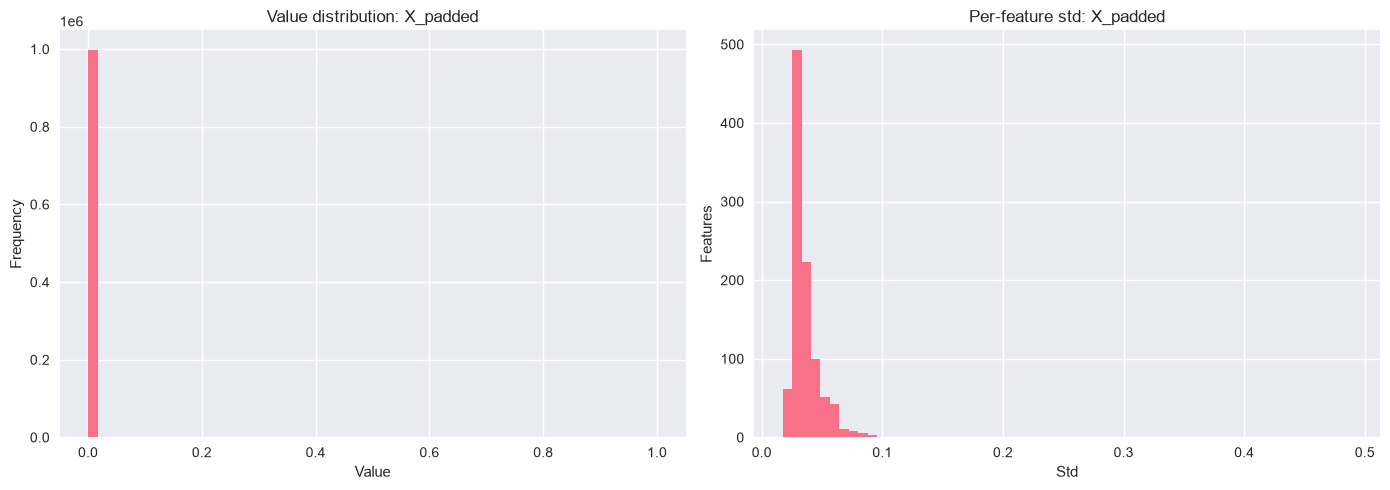

[Y_target] shape=[14074, 1001] status=PASS
  min: 0.0
  max: 1.0
  mean: 0.003995933104306459
  std: 0.06308697164058685
  max_abs: 1.0
  vanishing_ratio: 0.9960040669860195
  exploding_ratio: 0.0
  dead_feature_ratio: 0.004995004995004995
  all_zero_rows_ratio: 0.0
  nan_count: 0
  inf_count: 0


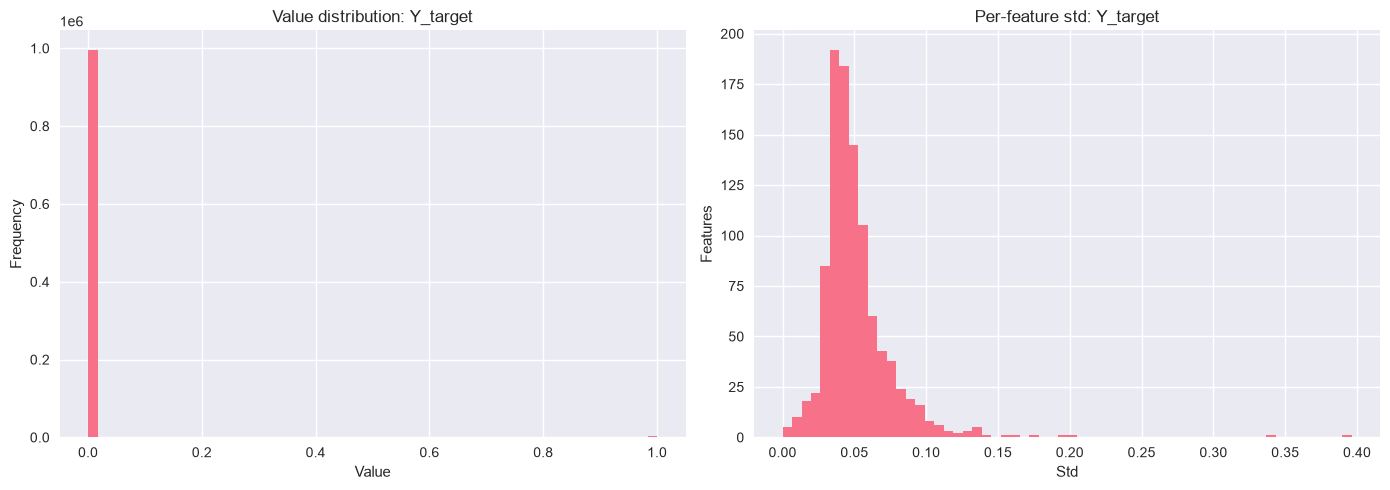

Dense RBM export not found at ../data/processed/X_rbm_dense.npy; dense validation skipped
Share of targets containing RARE_ITEM: 0.8050
Targets with no real item (excluded from evaluation): 1951
Integrity validation complete: no hard failures


In [5]:
reports = {}
reports['X_padded'] = validate_dataset(X_padded, 'X_padded', binary=True)
reports['Y_target'] = validate_dataset(Y, 'Y_target', binary=True)

if os.path.exists(DENSE_PATH):
    X_dense = np.load(DENSE_PATH)
    if X_dense.shape[0] != X_padded.shape[0]:
        raise ValueError(f"Dense export has {X_dense.shape[0]} rows, expected {X_padded.shape[0]}")
    reports['X_rbm_dense'] = validate_dataset(X_dense, 'X_rbm_dense', binary=False)
    del X_dense
else:
    print(f"Dense RBM export not found at {DENSE_PATH}; dense validation skipped")

print(f"Share of targets containing RARE_ITEM: {Y[:, RARE_IDX].mean():.4f}")
print(f"Targets with no real item (excluded from evaluation): {int((Y[:, 1:].sum(axis=1) == 0).sum())}")

hard_failures = [name for name, r in reports.items() if r['status'] == 'FAIL']
if hard_failures:
    raise ValueError(f"Integrity validation failed for: {hard_failures}")
print("Integrity validation complete: no hard failures")

In [6]:
history_mask = X_padded.sum(axis=2) > 0
transactions = []
for u in range(X_padded.shape[0]):
    for t in range(X_padded.shape[1]):
        if not history_mask[u, t]:
            continue
        items = np.flatnonzero(X_padded[u, t] > 0)
        items = items[items != RARE_IDX]
        if items.size > 0:
            transactions.append([int(i) for i in items])

print(f"Training baskets built from history only (targets excluded): {len(transactions)}")

pop_counts = np.zeros(VOCAB_SIZE, dtype=np.float64)
for basket in transactions:
    pop_counts[basket] += 1
pop_norm = pop_counts / max(pop_counts.max(), 1.0)
pop_norm[RARE_IDX] = 0.0

Training baskets built from history only (targets excluded): 56680


In [7]:
def evaluate_scores(scores, Y_true, k_values=K_VALUES):
    truth = Y_true[:, 1:] > 0
    cand = scores[:, 1:]
    n_true = truth.sum(axis=1)
    valid = n_true > 0
    truth_v = truth[valid]
    cand_v = cand[valid]
    n_true_v = n_true[valid]
    order = np.argsort(-cand_v, axis=1, kind='stable')
    results = {}
    for k in k_values:
        top = order[:, :k]
        hits = np.take_along_axis(truth_v, top, axis=1).sum(axis=1)
        results[k] = {
            'HitRatio': float(np.mean(hits > 0)),
            'Recall': float(np.mean(hits / n_true_v)),
            'Precision': float(np.mean(hits / k)),
            'evaluated_users': int(valid.sum())
        }
    return results

In [8]:
mp_scores = np.tile(pop_norm.astype(np.float32), (X_padded.shape[0], 1))
mp_results = evaluate_scores(mp_scores, Y)
print("Most Popular baseline built from training history")

Most Popular baseline built from training history


In [9]:
te = TransactionEncoder()
te_array = te.fit(transactions).transform(transactions)
basket_df = pd.DataFrame(te_array, columns=te.columns_)

frequent_itemsets = fpgrowth(basket_df, min_support=MIN_SUPPORT, use_colnames=True)
print(f"Frequent itemsets: {len(frequent_itemsets)}")

if frequent_itemsets.empty:
    rules = pd.DataFrame(columns=['antecedents', 'consequents', 'confidence'])
else:
    rules = association_rules(frequent_itemsets, metric='confidence', min_threshold=MIN_CONFIDENCE)
print(f"Association rules (confidence >= {MIN_CONFIDENCE}): {len(rules)}")
rules.to_csv(f'{REPORT_DIR}/fpgrowth_rules.csv', index=False)

X_hist = (X_padded > 0).any(axis=1)
rule_scores = np.zeros((X_padded.shape[0], VOCAB_SIZE), dtype=np.float32)
for _, rule in rules.iterrows():
    ant = np.array(sorted(int(x) for x in rule['antecedents']), dtype=int)
    cons = np.array(sorted(int(x) for x in rule['consequents'] if int(x) != RARE_IDX), dtype=int)
    if cons.size == 0:
        continue
    match_rows = np.flatnonzero(X_hist[:, ant].all(axis=1))
    if match_rows.size == 0:
        continue
    idx = np.ix_(match_rows, cons)
    rule_scores[idx] = np.maximum(rule_scores[idx], float(rule['confidence']))

RULE_WEIGHT = 0.5
fp_scores = pop_norm.astype(np.float32)[None, :] + RULE_WEIGHT * rule_scores
fp_scores[:, RARE_IDX] = 0.0

coverage = float(np.mean(rule_scores.max(axis=1) >= MIN_CONFIDENCE))
print(f"Users with at least one matching rule: {coverage:.2%}")

fp_results = evaluate_scores(fp_scores, Y)

Frequent itemsets: 1211
Association rules (confidence >= 0.5): 130
Users with at least one matching rule: 27.71%


In [10]:
print(f"{'K':>4} | {'Model':<13} | {'HitRatio':>9} | {'Recall':>9} | {'Precision':>9}")
for k in K_VALUES:
    for label, res in [('Most Popular', mp_results), ('FP-Growth', fp_results)]:
        r = res[k]
        print(f"{k:>4} | {label:<13} | {r['HitRatio']:>9.4f} | {r['Recall']:>9.4f} | {r['Precision']:>9.4f}")
print(f"Evaluated users: {mp_results[K_VALUES[0]]['evaluated_users']}")

for k in K_VALUES:
    base = mp_results[k]['HitRatio']
    lift = (fp_results[k]['HitRatio'] - base) / max(base, 1e-12)
    print(f"K={k}: FP-Growth HitRatio lift over Most Popular: {lift:+.2%}")

   K | Model         |  HitRatio |    Recall | Precision
   1 | Most Popular  |    0.1533 |    0.0707 |    0.1533
   1 | FP-Growth     |    0.1533 |    0.0707 |    0.1533
   3 | Most Popular  |    0.1998 |    0.0927 |    0.0737
   3 | FP-Growth     |    0.2034 |    0.0930 |    0.0749
   5 | Most Popular  |    0.2347 |    0.1044 |    0.0527
   5 | FP-Growth     |    0.2374 |    0.1051 |    0.0538
   9 | Most Popular  |    0.2796 |    0.1219 |    0.0363
   9 | FP-Growth     |    0.2829 |    0.1234 |    0.0373
Evaluated users: 12123
K=1: FP-Growth HitRatio lift over Most Popular: +0.00%
K=3: FP-Growth HitRatio lift over Most Popular: +1.82%
K=5: FP-Growth HitRatio lift over Most Popular: +1.16%
K=9: FP-Growth HitRatio lift over Most Popular: +1.18%


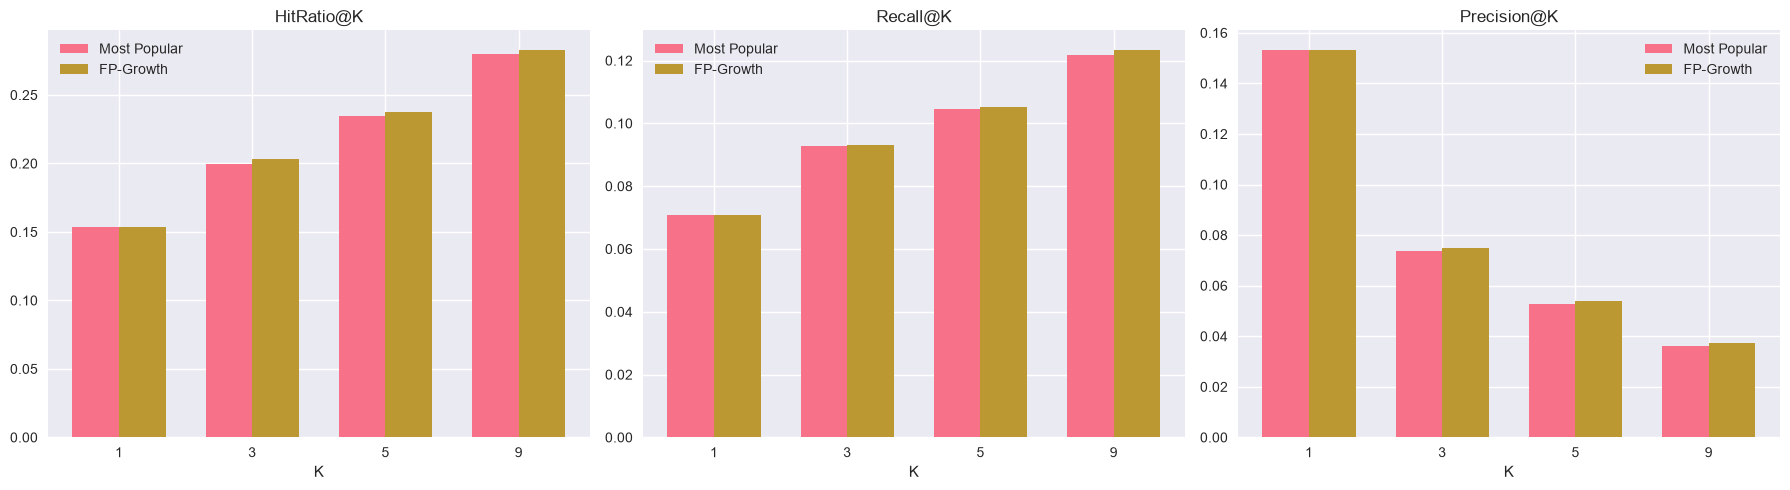

In [11]:
ks = K_VALUES
x = np.arange(len(ks))
w = 0.35
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, metric in zip(axes, ['HitRatio', 'Recall', 'Precision']):
    ax.bar(x - w / 2, [mp_results[k][metric] for k in ks], w, label='Most Popular')
    ax.bar(x + w / 2, [fp_results[k][metric] for k in ks], w, label='FP-Growth')
    ax.set_xticks(x)
    ax.set_xticklabels(ks)
    ax.set_xlabel('K')
    ax.set_title(f'{metric}@K')
    ax.legend()
plt.tight_layout()
plt.savefig(f'{VIS_DIR}/baseline_comparison.png')
plt.show()
plt.close()

In [12]:
baseline_report = {
    'config': {
        'VOCAB_SIZE': VOCAB_SIZE,
        'RARE_IDX': RARE_IDX,
        'K_VALUES': K_VALUES,
        'MIN_SUPPORT': MIN_SUPPORT,
        'MIN_CONFIDENCE': MIN_CONFIDENCE,
    },
    'validation': reports,
    'most_popular': {str(k): v for k, v in mp_results.items()},
    'fpgrowth': {str(k): v for k, v in fp_results.items()},
    'fpgrowth_coverage': coverage,
}
with open(f'{REPORT_DIR}/phase3_baseline_report.json', 'w') as f:
    json.dump(baseline_report, f, indent=2)

np.save(f'{PRED_DIR}/most_popular_scores.npy', mp_scores)
np.save(f'{PRED_DIR}/fpgrowth_scores.npy', fp_scores)
print(f"Saved report and score matrices to {REPORT_DIR} and {PRED_DIR}")

Saved report and score matrices to ../data/reports and ../data/predictions
